Pasul 1: Analiza relațiilor între surse (Harta Relațiilor)

In [3]:
!pip install osmnx folium mapclassify -q

[LOG] Initializare GEE...
[LOG] GEE Initializat.

[LOG] 0. Se genereaza gridul de 500m pentru Bucuresti...
[LOG] 0. Grid generat pe serverul GEE.

[LOG] 1. Extragere si agregare Landsat 9 LST...
[LOG] 1. Landsat 9 procesat.

[LOG] 2. Extragere si agregare Sentinel-2 NDVI...
[LOG] 2. Sentinel-2 procesat.

[LOG] 3. Extragere GHSL (Inaltime cladiri)...
[LOG] 3. GHSL procesat.

[LOG] 4. Se descarca datele din GEE in format GeoDataFrame...
[LOG] 4. Baza gridului GEE este gata: 856 randuri.

[LOG] 5. Incepe interogarea vectoriala prin OSMnx...
[LOG] 5.1. Descarcare si intersectie cladiri OSM...
    -> Incercare 1/5...
[LOG] 5.2. Descarcare si intersectie parcuri OSM...
    -> Incercare 1/5...
[LOG] 5.3. Descarcare si intersectie drumuri OSM...
    -> Incercare 1/5...
    -> Eroare: 'overpass-api.de' responded: 502 Bad Gateway # 502 Gateway Timeout

This Overpass API server is currently at capacity. All query workers are busy
and the request queue is full.

## What to do

Retry your request u

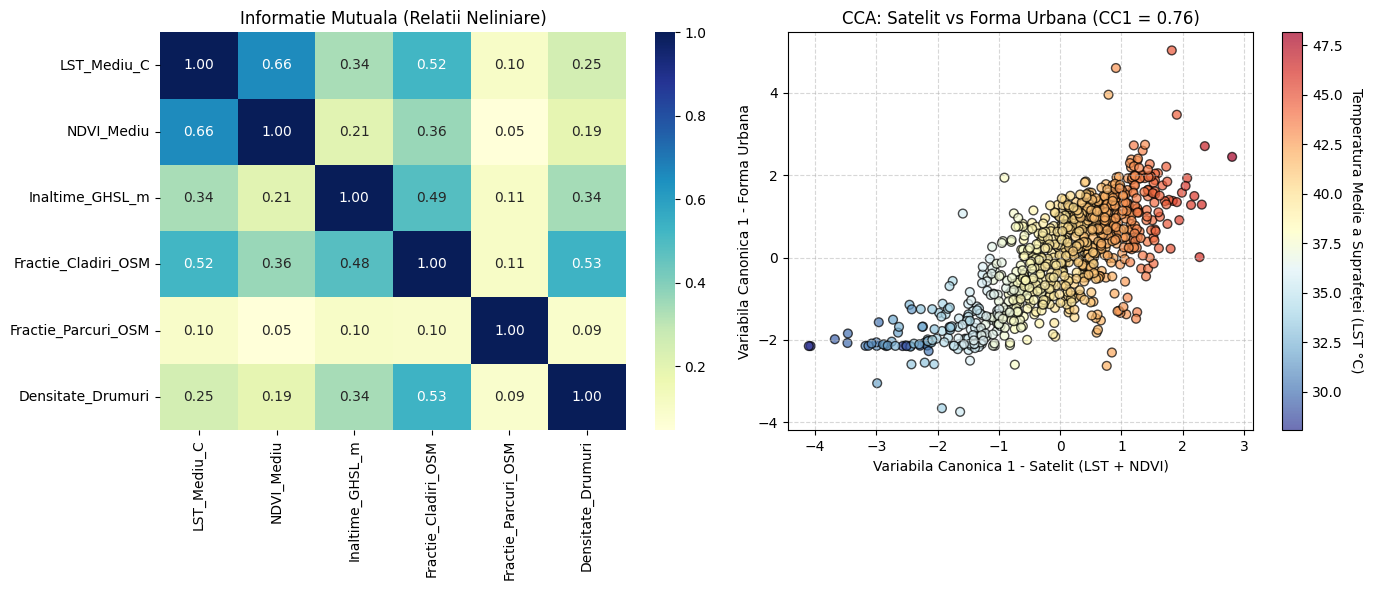

[LOG] Pasul 1 complet: Harta relațiilor cu legendă a fost generată și salvată cu succes!


In [4]:
# ==============================================================================
# PIPELINE COMPLET CP3: GENERARE MATRICE X (INDEPENDENT) + HARTA RELATIILOR (PASUL 1)
# ==============================================================================
import ee
import osmnx as ox
import time
import geopandas as gpd
import pandas as pd
import numpy as np
import warnings
from shapely.geometry import box
from IPython.display import display
import matplotlib.pyplot as plt
import seaborn as sns

# Biblioteci pentru CP3 (Relații)
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_regression
from sklearn.cross_decomposition import CCA
import libpysal
from esda.moran import Moran

warnings.filterwarnings('ignore')

# ------------------------------------------------------------------------------
# PARTEA 1: GENERAREA MATRICEI X (AUTONOMĂ)
# ------------------------------------------------------------------------------
print("[LOG] Initializare GEE...")
ee.Authenticate()
ee.Initialize(project='mede-511511')
print("[LOG] GEE Initializat.\n")

print("[LOG] 0. Se genereaza gridul de 500m pentru Bucuresti...")
bbox = [25.99, 44.38, 26.18, 44.50]
roi = ee.Geometry.Rectangle(bbox)
projection = ee.Projection('EPSG:32635')
grid_500m = ee.Geometry.Rectangle(bbox).coveringGrid(projection, 500)
aria_celula_m2 = 500 * 500
print("[LOG] 0. Grid generat pe serverul GEE.\n")

print("[LOG] 1. Extragere si agregare Landsat 9 LST...")
def extract_lst(image):
    thermal = image.select('ST_B10').multiply(0.00341802).add(149.0).subtract(273.15)
    return image.addBands(thermal.rename('LST_Celsius'))

l9_mean = (ee.ImageCollection("LANDSAT/LC09/C02/T1_L2")
           .filterBounds(roi)
           .filterDate('2026-06-01', '2026-08-31')
           .filter(ee.Filter.lt('CLOUD_COVER', 10))
           .map(extract_lst)
           .select('LST_Celsius')
           .mean())

grid_gee = l9_mean.reduceRegions(collection=grid_500m, reducer=ee.Reducer.mean(), scale=30)\
                  .map(lambda f: f.set('LST_Mediu_C', f.get('mean')))
print("[LOG] 1. Landsat 9 procesat.\n")

print("[LOG] 2. Extragere si agregare Sentinel-2 NDVI...")
def add_ndvi(image):
    return image.addBands(image.normalizedDifference(['B8', 'B4']).rename('NDVI'))

s2_mean = (ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
           .filterBounds(roi)
           .filterDate('2026-06-01', '2026-08-31')
           .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 10))
           .map(add_ndvi)
           .select('NDVI')
           .mean())

grid_gee = s2_mean.reduceRegions(collection=grid_gee, reducer=ee.Reducer.mean(), scale=10)\
                  .map(lambda f: f.set('NDVI_Mediu', f.get('mean')))
print("[LOG] 2. Sentinel-2 procesat.\n")

print("[LOG] 3. Extragere GHSL (Inaltime cladiri)...")
ghsl_height = ee.Image("JRC/GHSL/P2023A/GHS_BUILT_H/2018").select('built_height')
grid_gee = ghsl_height.reduceRegions(collection=grid_gee, reducer=ee.Reducer.mean(), scale=100)\
                      .map(lambda f: f.set('Inaltime_GHSL_m', f.get('mean')))
print("[LOG] 3. GHSL procesat.\n")

print("[LOG] 4. Se descarca datele din GEE in format GeoDataFrame...")
grid_gee = grid_gee.map(lambda f: ee.Feature(f).transform('EPSG:4326', 0.001))
features = grid_gee.getInfo()['features']

grid_gdf = gpd.GeoDataFrame.from_features(features)
grid_gdf = grid_gdf.set_crs("EPSG:4326", allow_override=True).to_crs("EPSG:32635")
grid_gdf['ID_Celula'] = range(len(grid_gdf))
grid_gdf['geometry'] = grid_gdf.geometry.buffer(0)

for col in ['mean']:
    if col in grid_gdf.columns:
        grid_gdf = grid_gdf.drop(columns=[col])
print(f"[LOG] 4. Baza gridului GEE este gata: {len(grid_gdf)} randuri.\n")

print("[LOG] 5. Incepe interogarea vectoriala prin OSMnx...")
ox.settings.requests_kwargs = {}
ox.settings.timeout = 600

def fetch_osm_with_retry(polygon, tags, max_retries=5):
    for attempt in range(max_retries):
        try:
            print(f"    -> Incercare {attempt + 1}/{max_retries}...")
            return ox.features_from_polygon(polygon=polygon, tags=tags)
        except Exception as e:
            print(f"    -> Eroare: {e}")
            wait_time = 10 * (2 ** attempt)
            print(f"    -> Asteptam {wait_time} secunde si reincercam...")
            time.sleep(wait_time)
    raise Exception("Overpass API nu raspunde.")

roi_poly = box(bbox[0], bbox[1], bbox[2], bbox[3])

print("[LOG] 5.1. Descarcare si intersectie cladiri OSM...")
osm_buildings = fetch_osm_with_retry(roi_poly, tags={'building': True}).to_crs("EPSG:32635")
osm_buildings = osm_buildings[osm_buildings.geom_type.isin(['Polygon', 'MultiPolygon'])].reset_index()
osm_buildings['geometry'] = osm_buildings.geometry.buffer(0)
intersect_bld = gpd.overlay(grid_gdf[['ID_Celula', 'geometry']], osm_buildings[['geometry']], how='intersection')
intersect_bld['aria'] = intersect_bld.geometry.area
aria_bld = intersect_bld.groupby('ID_Celula')['aria'].sum().reset_index(name='Aria_Cladiri_m2')

print("[LOG] 5.2. Descarcare si intersectie parcuri OSM...")
osm_parks = fetch_osm_with_retry(roi_poly, tags={'leisure': 'park', 'landuse': ['grass', 'forest']}).to_crs("EPSG:32635")
osm_parks = osm_parks[osm_parks.geom_type.isin(['Polygon', 'MultiPolygon'])].reset_index()
osm_parks['geometry'] = osm_parks.geometry.buffer(0)
intersect_prk = gpd.overlay(grid_gdf[['ID_Celula', 'geometry']], osm_parks[['geometry']], how='intersection')
intersect_prk['aria'] = intersect_prk.geometry.area
aria_prk = intersect_prk.groupby('ID_Celula')['aria'].sum().reset_index(name='Aria_Parcuri_m2')

print("[LOG] 5.3. Descarcare si intersectie drumuri OSM...")
tags_drumuri = {'highway': ['motorway', 'trunk', 'primary', 'secondary', 'tertiary', 'unclassified', 'residential']}
osm_roads = fetch_osm_with_retry(roi_poly, tags=tags_drumuri).to_crs("EPSG:32635")
osm_roads = osm_roads[osm_roads.geom_type.isin(['LineString', 'MultiLineString'])].reset_index()
intersect_rds = gpd.overlay(grid_gdf[['ID_Celula', 'geometry']], osm_roads[['geometry']], how='intersection', keep_geom_type=False)
intersect_rds['lungime'] = intersect_rds.geometry.length
lungime_rds = intersect_rds.groupby('ID_Celula')['lungime'].sum().reset_index(name='Lungime_Drumuri_m')

print("[LOG] 5.4. Imbinare rezultate OSM cu gridul principal...")
grid_gdf = grid_gdf.merge(aria_bld, on='ID_Celula', how='left').fillna({'Aria_Cladiri_m2': 0})
grid_gdf = grid_gdf.merge(aria_prk, on='ID_Celula', how='left').fillna({'Aria_Parcuri_m2': 0})
grid_gdf = grid_gdf.merge(lungime_rds, on='ID_Celula', how='left').fillna({'Lungime_Drumuri_m': 0})

grid_gdf['Fractie_Cladiri_OSM'] = grid_gdf['Aria_Cladiri_m2'] / aria_celula_m2
grid_gdf['Fractie_Parcuri_OSM'] = grid_gdf['Aria_Parcuri_m2'] / aria_celula_m2
grid_gdf['Densitate_Drumuri'] = grid_gdf['Lungime_Drumuri_m'] / aria_celula_m2

print("[LOG] 6. Tratare goluri si finalizare Matrice X...")
coloane_cu_geometrie = [
    'ID_Celula', 'LST_Mediu_C', 'NDVI_Mediu', 'Inaltime_GHSL_m',
    'Fractie_Cladiri_OSM', 'Fractie_Parcuri_OSM', 'Densitate_Drumuri', 'geometry'
]
matrice_X_gdf = grid_gdf.dropna(subset=['LST_Mediu_C', 'NDVI_Mediu', 'Inaltime_GHSL_m'])[coloane_cu_geometrie].copy()
matrice_X_gdf.reset_index(drop=True, inplace=True)
print(f"--- MATRICEA X GENERATA: {matrice_X_gdf.shape[0]} eșantioane x 6 trăsături ---\n")


# ------------------------------------------------------------------------------
# PARTEA 2: CP3 - PASUL 1 (HARTA RELAȚIILOR: MI, CCA, MORAN'S I)
# ------------------------------------------------------------------------------
print("=== INCEPERE ANALIZA RELATII INTRE SURSE (CP3 - PASUL 1) ===")

trasaturi = [
    'LST_Mediu_C', 'NDVI_Mediu', 'Inaltime_GHSL_m',
    'Fractie_Cladiri_OSM', 'Fractie_Parcuri_OSM', 'Densitate_Drumuri'
]

X_raw = matrice_X_gdf[trasaturi].copy()
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X_raw), columns=trasaturi)

# Adaugam coordonatele centroizilor in sistem metric pentru Moran's I
centroizi = matrice_X_gdf.geometry.centroid
matrice_X_gdf['X_coord'] = centroizi.x
matrice_X_gdf['Y_coord'] = centroizi.y

# 1. Informatie Mutuala (MI)
print("[LOG] Se calculeaza Matricea de Informatie Mutuala (MI)...")
mi_matrix = pd.DataFrame(np.zeros((len(trasaturi), len(trasaturi))), index=trasaturi, columns=trasaturi)
for i, col_x in enumerate(trasaturi):
    for j, col_y in enumerate(trasaturi):
        if i == j:
            mi_matrix.iloc[i, j] = 1.0
        else:
            mi_val = mutual_info_regression(X_scaled[[col_x]], X_scaled[col_y], random_state=42)[0]
            mi_matrix.iloc[i, j] = mi_val

# 2. Canonical Correlation Analysis (CCA)
print("[LOG] Se ruleaza Analiza Corelației Canonice (CCA)...")
mod_satelit = X_scaled[['LST_Mediu_C', 'NDVI_Mediu']]
mod_urban = X_scaled[['Inaltime_GHSL_m', 'Fractie_Cladiri_OSM', 'Fractie_Parcuri_OSM', 'Densitate_Drumuri']]

cca = CCA(n_components=2)
U, V = cca.fit_transform(mod_satelit, mod_urban)
cor_canonica_1 = np.corrcoef(U[:, 0], V[:, 0])[0, 1]
cor_canonica_2 = np.corrcoef(U[:, 1], V[:, 1])[0, 1]

print(f"  -> Corelatie canonica CC1: {cor_canonica_1:.4f}")
print(f"  -> Corelatie canonica CC2: {cor_canonica_2:.4f}")

# 3. Autocorelatie Spatiala (Moran's I)
print("[LOG] Se calculeaza Autocorelatia Spatiala (Moran's I) pentru LST...")
w = libpysal.weights.KNN.from_dataframe(matrice_X_gdf, k=8)
w.transform = 'r'
moran_lst = Moran(matrice_X_gdf['LST_Mediu_C'], w)
print(f"  -> Indice Moran's I (LST): {moran_lst.I:.4f} (p-value: {moran_lst.p_sim:.4f})")

# Vizualizare si salvare

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Grafic 1: Heatmap Informatie Mutuala
sns.heatmap(mi_matrix, annot=True, fmt=".2f", cmap="YlGnBu", ax=axes[0], cbar=True)
axes[0].set_title("Informatie Mutuala (Relatii Neliniare)")

# Grafic 2: Scatter plot CCA cu legendară (colorbar) adăugată
scatter = axes[1].scatter(
    U[:, 0], V[:, 0],
    c=matrice_X_gdf['LST_Mediu_C'],
    cmap='RdYlBu_r',
    alpha=0.7,
    edgecolors='k',
    s=40
)
axes[1].set_title(f"CCA: Satelit vs Forma Urbana (CC1 = {cor_canonica_1:.2f})")
axes[1].set_xlabel("Variabila Canonica 1 - Satelit (LST + NDVI)")
axes[1].set_ylabel("Variabila Canonica 1 - Forma Urbana")
axes[1].grid(True, linestyle='--', alpha=0.5)

# Aici adăugăm bara de culori (legenda termică) pentru graficul din dreapta
cbar = plt.colorbar(scatter, ax=axes[1])
cbar.set_label('Temperatura Medie a Suprafeței (LST °C)', rotation=270, labelpad=15)

plt.tight_layout()
plt.savefig("harta_relatiilor_cp3.png", dpi=300)
plt.show()
print("[LOG] Pasul 1 complet: Harta relațiilor cu legendă a fost generată și salvată cu succes!")

Pasul 2: Protocolul experimental și Split-ul spațial

Protocolul pentru Pasul 2:
Split Spațial Geografic: Împărțim celulele din București pe o axă geografică (de exemplu, pe axa Nord-Sud sau Est-Vest folosind coordonatele centroizilor X_coord sau Y_coord), separând fizic zonele de antrenare de cele de testare (păstrând proporția de 80% / 20%).
Aplicăm StandardScaler().fit(X_train) exclusiv pe setul de antrenare și apoi .transform(X_test) pe setul de test

In [5]:
# ==============================================================================
# CP3 - PASUL 2: PROTOCOL EXPERIMENTAL (SPLIT SPAȚIAL & SCALARE FĂRĂ LEAKAGE)
# ==============================================================================
from sklearn.model_selection import train_test_split

print("=== DEFINIREA PROTOCOLULUI EXPERIMENTAL (PASUL 2) ===")

# 1. Selectarea trăsăturilor pentru fuziunea completă
trasaturi = [
    'LST_Mediu_C', 'NDVI_Mediu', 'Inaltime_GHSL_m',
    'Fractie_Cladiri_OSM', 'Fractie_Parcuri_OSM', 'Densitate_Drumuri'
]

X = matrice_X_gdf[trasaturi].values
y = matrice_X_gdf['LST_Mediu_C'].values # Target-ul principal (Insula de Căldură)

# 2. Implementarea Split-ului Spațial (Fără Data Leakage spațial)
# Sortăm celulele după coordonata geografică Y (Nord-Sud) sau X (Est-Vest)
# și separăm geografic setul de test de cel de antrenare.
print("[LOG] Se aplică Split-ul Spațial pe baza coordonatelor geografice...")
df_sorted = matrice_X_gdf.sort_values(by='Y_coord').reset_index(drop=True)

# Tăiem geografic: primele 80% pentru antrenare, restul de 20% pentru testare
split_idx = int(len(df_sorted) * 0.8)

train_df = df_sorted.iloc[:split_idx]
test_df = df_sorted.iloc[split_idx:]

X_train = train_df[trasaturi].values
X_test = test_df[trasaturi].values

print(f"  -> Eșantioane antrenare (Train - Sud/Centru): {X_train.shape[0]}")
print(f"  -> Eșantioane testare (Test - Nord): {X_test.shape[0]}")

# 3. Standardizare Corectă (Fără Data Leakage numeric)
print("[LOG] Se aplică StandardScaler() exclusiv pe setul de antrenare...")
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train) # Fit + Transform doar pe Train
X_test_scaled = scaler.transform(X_test)       # Doar Transform pe Test

print("[LOG] Pasul 2 complet: Protocolul experimental spațial și standardizarea au fost configurate cu succes!")

=== DEFINIREA PROTOCOLULUI EXPERIMENTAL (PASUL 2) ===
[LOG] Se aplică Split-ul Spațial pe baza coordonatelor geografice...
  -> Eșantioane antrenare (Train - Sud/Centru): 676
  -> Eșantioane testare (Test - Nord): 169
[LOG] Se aplică StandardScaler() exclusiv pe setul de antrenare...
[LOG] Pasul 2 complet: Protocolul experimental spațial și standardizarea au fost configurate cu succes!


Pasul 3: Comparația Reprezentărilor - PCA Baseline vs. UMAP (Uniform Manifold Approximation and Projection)

In [6]:
# ==============================================================================
# CP3 - PASUL 3: COMPARATIA REPREZENTARILOR (PCA VS. UMAP PE SURSE SI SEED-URI)
# ==============================================================================
import numpy as np
import pandas as pd
import umap
from sklearn.decomposition import PCA
from sklearn.manifold import trustworthiness
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

print("=== INCEPERE PASUL 3: COMPARATIA REPREZENTARILOR (PCA VS UMAP) ===")

# 1. Definirea celor 4 configurații de date (surse separate vs. combinate)
subseturi_surse = {
    "1. Doar Forma Urbana (OSM)": ['Fractie_Cladiri_OSM', 'Fractie_Parcuri_OSM', 'Densitate_Drumuri'],
    "2. Doar Satelit (Optic + Termic)": ['LST_Mediu_C', 'NDVI_Mediu'],
    "3. GHSL + Satelit": ['Inaltime_GHSL_m', 'LST_Mediu_C', 'NDVI_Mediu'],
    "4. Toate Sursele (Fuziune 6D)": ['LST_Mediu_C', 'NDVI_Mediu', 'Inaltime_GHSL_m',
                                     'Fractie_Cladiri_OSM', 'Fractie_Parcuri_OSM', 'Densitate_Drumuri']
}

# Parametri experimentali pentru stabilitate
seeds = [42, 100, 2026, 7, 99]
k_dim = 2 # Numarul de dimensiuni pastrate pentru proiectie
rezultate_experimentale = []

for nume_subset, cols in subseturi_surse.items():
    print(f"[LOG] Evaluare subset surse: {nume_subset}...")

    for seed in seeds:
        # Păstrăm split-ul spațial geografic stabilit la Pasul 2 (pe baza coordonatei Y_coord)
        df_sorted = matrice_X_gdf.sort_values(by='Y_coord').reset_index(drop=True)
        split_idx = int(len(df_sorted) * 0.8)

        X_train = df_sorted.iloc[:split_idx][cols].values
        X_test = df_sorted.iloc[split_idx:][cols].values

        # Standardizare corectă (fără Data Leakage: fit doar pe train, transform pe test)
        scaler_sub = StandardScaler()
        X_train_s = scaler_sub.fit_transform(X_train)
        X_test_s = scaler_sub.transform(X_test)

        # --- 1. MODEL BASELINE: PCA (k=2) ---
        pca = PCA(n_components=min(k_dim, X_train_s.shape[1]), random_state=seed)
        X_train_pca = pca.fit_transform(X_train_s)
        X_test_pca = pca.transform(X_test_s)

        # Eroare de reconstrucție MSE pe setul de test
        X_test_recon = pca.inverse_transform(X_test_pca)
        mse_pca = mean_squared_error(X_test_s, X_test_recon)

        # Trustworthiness (calitatea păstrării vecinilor locali pe test)
        tw_pca = trustworthiness(X_test_s, X_test_pca, n_neighbors=10)

        rezultate_experimentale.append({
            "Subset Surse": nume_subset,
            "Metoda": "PCA (Baseline)",
            "Seed": seed,
            "Trustworthiness": tw_pca,
            "MSE Reconstructie": mse_pca,
            "Varianta Explicata": sum(pca.explained_variance_ratio_)
        })

        # --- 2. METODA ALTERNATIVĂ: UMAP (k=2) ---
        reducer_umap = umap.UMAP(n_components=k_dim, random_state=seed, n_neighbors=15, min_dist=0.1)
        X_train_umap = reducer_umap.fit_transform(X_train_s)
        X_test_umap = reducer_umap.transform(X_test_s)

        tw_umap = trustworthiness(X_test_s, X_test_umap, n_neighbors=10)

        rezultate_experimentale.append({
            "Subset Surse": nume_subset,
            "Metoda": "UMAP (Alternativa)",
            "Seed": seed,
            "Trustworthiness": tw_umap,
            "MSE Reconstructie": np.nan, # UMAP este non-parametric și nu oferă o reconstrucție liniară directă
            "Varianta Explicata": np.nan
        })

# 2. Agregarea statistică pe cele 5 seed-uri (Media ± Deviația Standard)
df_rezultate = pd.DataFrame(rezultate_experimentale)
tabel_central = df_rezultate.groupby(["Subset Surse", "Metoda"]).agg({
    "Trustworthiness": lambda x: f"{x.mean():.3f} ± {x.std():.3f}",
    "MSE Reconstructie": lambda x: f"{x.mean():.3f} ± {x.std():.3f}" if not x.isna().all() else "N/A",
    "Varianta Explicata": lambda x: f"{x.mean()*100:.1f}%" if not x.isna().all() else "N/A"
}).reset_index()

print("\n================================================================================")
print(" TABELUL CENTRAL CP3: REPREZENTARI VS. PCA (PE SEED-URI, CU INTERVALE)")
print("================================================================================")
display(tabel_central)

# Salvare tabel central pentru Slide-ul 2 și raportul de articol
tabel_central.to_csv("tabel_central_cp3_reprezentari.csv", index=False)
print("\n[LOG] Pasul 3 complet: Tabelul central comparativ a fost generat și salvat ca 'tabel_central_cp3_reprezentari.csv'.")

=== INCEPERE PASUL 3: COMPARATIA REPREZENTARILOR (PCA VS UMAP) ===
[LOG] Evaluare subset surse: 1. Doar Forma Urbana (OSM)...
[LOG] Evaluare subset surse: 2. Doar Satelit (Optic + Termic)...
[LOG] Evaluare subset surse: 3. GHSL + Satelit...
[LOG] Evaluare subset surse: 4. Toate Sursele (Fuziune 6D)...

 TABELUL CENTRAL CP3: REPREZENTARI VS. PCA (PE SEED-URI, CU INTERVALE)


,Subset Surse,Metoda,Trustworthiness,MSE Reconstructie,Varianta Explicata
0,1. Doar Forma Urbana (OSM),PCA (Baseline),0.923 ± 0.000,0.097 ± 0.000,86.2%
1,1. Doar Forma Urbana (OSM),UMAP (Alternativa),0.974 ± 0.004,N/A,N/A
2,2. Doar Satelit (Optic + Termic),PCA (Baseline),1.000 ± 0.000,0.000 ± 0.000,100.0%
3,2. Doar Satelit (Optic + Termic),UMAP (Alternativa),0.987 ± 0.001,N/A,N/A
4,3. GHSL + Satelit,PCA (Baseline),0.970 ± 0.000,0.099 ± 0.000,88.3%
5,3. GHSL + Satelit,UMAP (Alternativa),0.969 ± 0.000,N/A,N/A
6,4. Toate Sursele (Fuziune 6D),PCA (Baseline),0.938 ± 0.000,0.217 ± 0.000,69.9%
7,4. Toate Sursele (Fuziune 6D),UMAP (Alternativa),0.941 ± 0.003,N/A,N/A



[LOG] Pasul 3 complet: Tabelul central comparativ a fost generat și salvat ca 'tabel_central_cp3_reprezentari.csv'.


In [8]:
# ==============================================================================
# AFIȘAREA REZULTATELOR DETALIATE PE FIECARE SEED ÎN PARTE
# ==============================================================================

# Convertim lista de dicționari direct într-un DataFrame detaliat
df_detaliat = pd.DataFrame(rezultate_experimentale)

# Redenumim sau formatăm coloanele pentru a fi ușor de citit
df_detaliat['Varianta Explicata (%)'] = (df_detaliat['Varianta Explicata'] * 100).round(2)
df_detaliat['Trustworthiness'] = df_detaliat['Trustworthiness'].round(4)
df_detaliat['MSE Reconstructie'] = df_detaliat['MSE Reconstructie'].round(4)

print("\n================================================================================")
print(" TABEL DETALIAT CP3: TOATE REZULTATELE PE FIECARE SEED (N = 5)")
print("================================================================================")
display(df_detaliat)

# Opțional: Poți salva și acest tabel detaliat în format CSV dacă îl vrei în repo
df_detaliat.to_csv("tabel_detaliat_seeduri_cp3.csv", index=False)
print("\n[LOG] Tabelul detaliat pe seed-uri a fost salvat ca 'tabel_detaliat_seeduri_cp3.csv'.")


 TABEL DETALIAT CP3: TOATE REZULTATELE PE FIECARE SEED (N = 5)


,Subset Surse,Metoda,Seed,Trustworthiness,MSE Reconstructie,Varianta Explicata,Varianta Explicata (%)
0,1. Doar Forma Urbana (OSM),PCA (Baseline),42,0.9226,0.0968,0.862078,86.21
1,1. Doar Forma Urbana (OSM),UMAP (Alternativa),42,0.9747,NaN,NaN,NaN
2,1. Doar Forma Urbana (OSM),PCA (Baseline),100,0.9226,0.0968,0.862078,86.21
3,1. Doar Forma Urbana (OSM),UMAP (Alternativa),100,0.9724,NaN,NaN,NaN
4,1. Doar Forma Urbana (OSM),PCA (Baseline),2026,0.9226,0.0968,0.862078,86.21
5,1. Doar Forma Urbana (OSM),UMAP (Alternativa),2026,0.9769,NaN,NaN,NaN
6,1. Doar Forma Urbana (OSM),PCA (Baseline),7,0.9226,0.0968,0.862078,86.21
7,1. Doar Forma Urbana (OSM),UMAP (Alternativa),7,0.9769,NaN,NaN,NaN
8,1. Doar Forma Urbana (OSM),PCA (Baseline),99,0.9226,0.0968,0.862078,86.21
9,1. Doar Forma Urbana (OSM),UMAP (Alternativa),99,0.9679,NaN,NaN,NaN



[LOG] Tabelul detaliat pe seed-uri a fost salvat ca 'tabel_detaliat_seeduri_cp3.csv'.
